# <span style="color:red"> Lecture 8 Exercises </span>

In [1]:
# set-up code

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

carfeatures = pd.read_csv("data/features.csv")
car_cols = carfeatures.columns
car_colnames = car_cols.values

df_ht_wt = pd.read_csv("data/SOCR-HeightWeight.csv")

<font size = "4">

**Exercise**: Extract the weight and acceleration variables

In [2]:
# SOLUTION 1: Just use names
sol_1 = carfeatures[["weight", "acceleration"]]


# SOLUTION 2: Use names with an intermediate list variable
desired_variables = ["weight", "acceleration"]
sol_2 = carfeatures[desired_variables]

# SOLUTION 3: Use car_cols variable
sol_3 = carfeatures[[car_cols[4], car_cols[5]]]

# SOLUTION 4: Use car_colnames variable
relevant_vars = [car_colnames[4], car_colnames[5]]
sol_4 = carfeatures[relevant_vars]

sol_4

,weight,acceleration
0,3504,12.0
1,3693,11.5
2,3436,11.0
3,3433,12.0
4,3449,10.5
...,...,...
393,2790,15.6
394,2130,24.6
395,2295,11.6
396,2625,18.6


<font size = "4">

**Exercise**: Extract the displacement, horsepower, and vehicle_id variables

In [3]:
# SOLUTION 1: Use names and intermediate variable
my_variables = ["displacement", "horsepower", "vehicle_id"]
sol_1 = carfeatures[my_variables]

# SOLUTION 2: Use car_cols
sol_2 = carfeatures[[car_cols[2], car_cols[3], car_cols[6]]]

sol_2

,displacement,horsepower,vehicle_id
0,307,130,C-1689780
1,350,165,B-1689791
2,318,150,P-1689802
3,304,150,A-1689813
4,302,140,F-1689824
...,...,...,...
393,140,86,F-1694103
394,97,52,V-1694114
395,135,84,D-1694125
396,120,79,F-1694136


<font size = "4">

**Exercise:** Extract the columns corresponding to displacement, horsepower, and weight for all cars using ``.iloc``. The column indices should be of the form ``start:stop`` for appropriate integers ``start`` and ``stop``

In [4]:
# SOLUTION

sol = carfeatures.iloc[:, 2:5]

sol

,displacement,horsepower,weight
0,307,130,3504
1,350,165,3693
2,318,150,3436
3,304,150,3433
4,302,140,3449
...,...,...,...
393,140,86,2790
394,97,52,2130
395,135,84,2295
396,120,79,2625


<font size = "4">

**Exercise:** Extract the weight, acceleration, and vehicle_id information for cars 28, 29, 30, 31, 32 using ":" for both row and column indices

In [5]:
# SOLUTION 1 - column indices with explicit start and stop
sol_1 = carfeatures.iloc[28:33, 4:7]

# SOLUTION 2 - tell .iloc to "go all the way to the end" for column indices

sol_2 = carfeatures.iloc[28:33, 4:]

sol_2


,weight,acceleration,vehicle_id
28,4732,18.5,H-1690088
29,2130,14.5,D-1690099
30,2264,15.5,C-1690110
31,2228,14.0,T-1690121
32,2046,19.0,F-1690132


<font size = "4">

**Exercise:** Create a dataset ``car_ascendingweight`` which sorts the cars from lowest to highest weight. Then extract the subset of the data corresponding to the 5 cars with the lowest weight (all their features, not just their weight)

In [6]:
# SOLUTION
car_ascendingweight = carfeatures.sort_values(by="weight")
sol = car_ascendingweight.iloc[:5, :]

sol

,mpg,cylinders,displacement,horsepower,weight,acceleration,vehicle_id
54,35.0,4,72,69,1613,18.0,D-1690374
144,31.0,4,76,52,1649,16.5,T-1691364
343,39.1,4,79,58,1755,16.9,T-1693553
345,35.1,4,81,60,1760,16.1,H-1693575
53,31.0,4,71,65,1773,19.0,T-1690363


<font size = "4">

**Recall:** In Lecture 8, we created two Pandas series by converting the height/weight data from inches/pounds to meters/kg:

In [7]:
# Grab height and weight and convert to correct units

def pounds_to_kg(wt):
    return wt*0.45359237

def inches_to_meters(ht):
    ht_mm = ht*25.4
    return ht_mm*1e-3

ht_inch = df_ht_wt["Height(Inches)"]
wt_lbs = df_ht_wt["Weight(Pounds)"]

ht_meters = ht_inch.apply(inches_to_meters)
ht_meters.name = "Height(Meters)"
wt_kg = wt_lbs.apply(pounds_to_kg)
wt_kg.name = "Weight(Kilograms)"

<font size = "4">

**Exercise**: Repeat the operations in the last cell, but grab ``ht_inch`` and ``wt_lbs`` using ``.iloc`` instead of the column names

In [8]:
df_ht_wt

,Height(Inches),Weight(Pounds)
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971
...,...,...
24995,69.50215,118.0312
24996,64.54826,120.1932
24997,64.69855,118.2655
24998,67.52918,132.2682


In [9]:
# SOLUTION

def pounds_to_kg(wt):
    return wt*0.45359237

def inches_to_meters(ht):
    ht_mm = ht*25.4
    return ht_mm*1e-3

ht_inch = df_ht_wt.iloc[:, 0]
wt_lbs = df_ht_wt.iloc[:, 1]

ht_meters = ht_inch.apply(inches_to_meters)
ht_meters.name = "Height(Meters)"
wt_kg = wt_lbs.apply(pounds_to_kg)
wt_kg.name = "Weight(Kilograms)"

<font size = "4">

**Exercise:** Subset the (carfeatures) data, gathering all cars with exactly 8 cylinders and mpg $\ge$ 25.

In [10]:
# SOLUTION #1 - input the string directly into .query
sol_1 = carfeatures.query("cylinders == 8 and mpg >= 25")

# SOLUTION #2 - Define an intermediate string
my_expression = "cylinders == 8 and mpg >= 25"
sol_2 = carfeatures.query(my_expression)

sol_2

,mpg,cylinders,displacement,horsepower,weight,acceleration,vehicle_id
364,26.6,8,350,105,3725,19.0,O-1693784


<font size="4">

**Exercise:** Compute a histogram of "mpg" by cylinder count for cars with 4, 6, and 8 cylinders. Here is what it might look like (using a fake dataset):

<img src="data/fake_histogram.png" alt="drawing" width="400"/>


You can make the histograms transparent by adjusting ```alpha``` in

```python
    plt.hist(x = ..., alpha = 0.5)
```

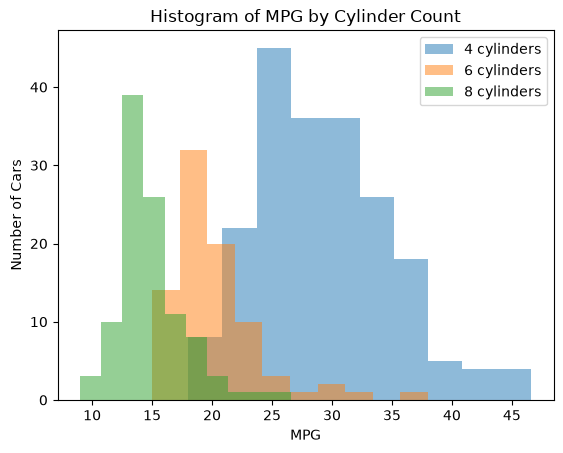

In [11]:
cylinder_vals = [4, 6, 8]

for cyl in cylinder_vals:
    df = carfeatures.query("cylinders == @cyl")
    plt.hist(x = df["mpg"], alpha = 0.5)

cylinder_labels = ["4 cylinders", "6 cylinders", "8 cylinders"]
plt.legend(labels = cylinder_labels)
plt.xlabel("MPG")
plt.ylabel("Number of Cars")
plt.title("Histogram of MPG by Cylinder Count")
plt.show()